    Sample_ID  Gene_01  Gene_02  Gene_03  Gene_04  Gene_05  Gene_06  Gene_07  \
0  Sample_001    5.745    4.793    5.972    7.285    4.649    4.649    7.369   
1  Sample_002    5.486    4.422    3.985    5.918    6.546    6.397    3.741   
2  Sample_003    2.877    4.369    4.486    3.797    4.758    5.606    7.829   
3  Sample_004    5.376    5.520    3.980    5.348    5.440    3.928    7.799   
4  Sample_005    5.537    5.841    6.625    6.581    2.933    3.593    5.773   

   Gene_08  Gene_09  ...  Gene_42  Gene_43  Gene_44  Gene_45  Gene_46  \
0    6.151    4.296  ...    5.257    4.827    4.548    2.782    3.920   
1    4.536    5.497  ...    6.453    3.947    4.509    4.412    2.805   
2    5.262    5.386  ...    6.961    2.589    5.277    5.390    6.173   
3    5.711    3.213  ...    6.285    5.321    3.131    5.260    5.578   
4    5.771    5.773  ...    4.828    5.757    6.299    3.200    4.498   

   Gene_47  Gene_48  Gene_49  Gene_50    Class  
0    4.309    6.586    5.515   

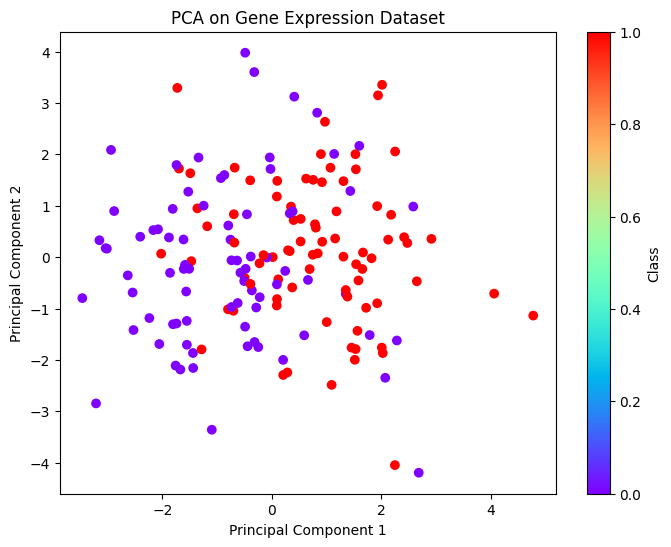

In [2]:
# Import libraries
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.decomposition import PCA
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, confusion_matrix

# Load dataset
data = pd.read_csv("/content/MLT Task 5 Dataset.csv")

# Check dataset
print(data.head())

# Separate features and target
X = data.iloc[:, 1:-1].values
y = data.iloc[:, -1].values

# Encode class labels
le = LabelEncoder()
y = le.fit_transform(y)

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# Standardization
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# PCA
pca = PCA(n_components=2)
X_train_pca = pca.fit_transform(X_train)
X_test_pca = pca.transform(X_test)

# Classification
clf = RandomForestClassifier(random_state=42)
clf.fit(X_train_pca, y_train)

y_pred = clf.predict(X_test_pca)

# Output
print("PCA Accuracy:", accuracy_score(y_test, y_pred))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))

# PCA Scatter Plot
plt.figure(figsize=(8, 6))
plt.scatter(
    X_train_pca[:, 0],
    X_train_pca[:, 1],
    c=y_train,
    cmap="rainbow"
)
plt.xlabel("Principal Component 1")
plt.ylabel("Principal Component 2")
plt.title("PCA on Gene Expression Dataset")
plt.colorbar(label="Class")
plt.show()